# Temporal Convolutional Networks for Sequence Modeling

This project implements a Temporal Convolutional Network (TCN) in PyTorch and compares it with LSTM and GRU models on three sequence-learning tasks: the Adding Problem, Copy Memory, and Sequential MNIST.

The implementation is based on the following paper:

**An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling**  
Shaojie Bai, J. Zico Kolter, Vladlen Koltun (2018)

[Research paper](https://arxiv.org/abs/1803.01271) · [Reference code](https://github.com/locuslab/TCN)

The experiments use smaller configurations to fit the available computing resources. Results are compared with the paper where the metrics and experimental settings allow a meaningful comparison.

In [2]:
# Check the TCN implementation

from pathlib import Path
import subprocess
import sys
import torch

REPO_URL = "https://github.com/PankajRao0004/DL-TCN-Project.git"
REPO_DIR = Path("/content/DL-TCN-Project")

# Retrieve the latest committed code, without duplicating the repository.
if REPO_DIR.exists():
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull", "--ff-only"],
        check=True
    )
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )

assert (REPO_DIR / "tcn.py").is_file(), (
    "tcn.py was not found in GitHub. Check that the file was pushed."
)

# Import the exact implementation from our repository.
sys.path.insert(0, str(REPO_DIR))
from tcn import TemporalConvNet

# Use a small model: this is a correctness test, not training.
torch.manual_seed(42)

model = TemporalConvNet(
    input_channels=2,
    channels=[8, 16, 16],
    kernel_size=3,
    dropout=0.1,
)
model.eval()

# Test 1: Output shape and residual connections.
x = torch.randn(4, 2, 64)

with torch.no_grad():
    y = model(x)

assert y.shape == (4, 16, 64), f"Unexpected shape: {y.shape}"
print("PASS: Output shape and residual connections.")

# Test 2: Changing future inputs must not change past outputs.
time_idx = 30
x_changed = x.clone()
x_changed[:, :, time_idx + 1:] += 10.0

with torch.no_grad():
    y_original = model(x)
    y_changed = model(x_changed)

assert torch.allclose(
    y_original[:, :, :time_idx + 1],
    y_changed[:, :, :time_idx + 1],
    atol=1e-6,
    rtol=0.0,
), "Causality test failed: future inputs changed past outputs."

print("PASS: Causality — future inputs do not affect past outputs.")

# Test 3: Verify the receptive field calculation.
expected_rf = 1 + 2 * (3 - 1) * (2**3 - 1)

assert model.receptive_field == expected_rf, (
    f"Expected receptive field {expected_rf}, "
    f"got {model.receptive_field}"
)

print(f"PASS: Receptive field = {model.receptive_field} time steps.")
print("\nAll TCN core tests passed.")

PASS: Output shape and residual connections.
PASS: Causality — future inputs do not affect past outputs.
PASS: Receptive field = 29 time steps.

All TCN core tests passed.


In [3]:

# Generate and validate Adding Problem data

import torch


def make_adding_data(num_samples, seed, seq_len=100):
    generator = torch.Generator().manual_seed(seed)

    values = torch.rand(
        num_samples, seq_len, generator=generator
    )
    positions = torch.rand(
        num_samples, seq_len, generator=generator
    ).argsort(dim=1)[:, :2]

    markers = torch.zeros_like(values)
    markers.scatter_(1, positions, 1.0)

    inputs = torch.stack([values, markers], dim=1)
    targets = (values * markers).sum(dim=1, keepdim=True)

    return inputs, targets


x_test, y_test = make_adding_data(
    num_samples=2048,
    seed=42,
    seq_len=100,
)

assert x_test.shape == (2048, 2, 100)
assert y_test.shape == (2048, 1)
assert torch.all(x_test[:, 1, :].sum(dim=1) == 2)

calculated_targets = (
    x_test[:, 0, :] * x_test[:, 1, :]
).sum(dim=1, keepdim=True)

assert torch.allclose(y_test, calculated_targets)

baseline_mse = ((y_test - 1.0) ** 2).mean().item()

print("PASS: Input and target shapes.")
print("PASS: Exactly two marked positions per sequence.")
print("PASS: Targets match the marked values.")
print(f"Constant-prediction baseline MSE: {baseline_mse:.4f}")


PASS: Input and target shapes.
PASS: Exactly two marked positions per sequence.
PASS: Targets match the marked values.
Constant-prediction baseline MSE: 0.1682


In [4]:
# Train and compare models on the Adding Problem

import csv
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

SEQ_LEN = 100
TRAIN_SIZE = 4096
VAL_SIZE = 1024
TEST_SIZE = 2048
BATCH_SIZE = 128
EPOCHS = 20





train_x, train_y = make_adding_data(TRAIN_SIZE, 101)
val_x, val_y = make_adding_data(VAL_SIZE, 202)
test_x, test_y = make_adding_data(TEST_SIZE, 303)

train_x, train_y = train_x.to(device), train_y.to(device)
val_x, val_y = val_x.to(device), val_y.to(device)
test_x, test_y = test_x.to(device), test_y.to(device)

assert torch.all(train_x[:, 1, :].sum(dim=1) == 2)
assert train_x.shape == (TRAIN_SIZE, 2, SEQ_LEN)

baseline_test_mse = ((test_y - 1.0) ** 2).mean().item()
print(f"Constant-prediction baseline MSE: {baseline_test_mse:.5f}")


class AddingTCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = TemporalConvNet(
            input_channels=2,
            channels=[16, 16, 16, 16, 16],
            kernel_size=3,
            dropout=0.1,
        )
        self.readout = nn.Linear(16, 1)

    def forward(self, x):
        features = self.backbone(x)
        return self.readout(features[:, :, -1])


class AddingRNN(nn.Module):
    def __init__(self, cell_type, hidden_size=48):
        super().__init__()

        if cell_type == "LSTM":
            self.rnn = nn.LSTM(2, hidden_size, batch_first=True)
        elif cell_type == "GRU":
            self.rnn = nn.GRU(2, hidden_size, batch_first=True)
        else:
            raise ValueError("cell_type must be LSTM or GRU")

        self.readout = nn.Linear(hidden_size, 1)

    def forward(self, x):
        outputs, _ = self.rnn(x.transpose(1, 2))
        return self.readout(outputs[:, -1, :])


def evaluate_mse(model, inputs, targets):
    model.eval()
    with torch.no_grad():
        return F.mse_loss(model(inputs), targets).item()


def train_model(name, model):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

    best_val_mse = float("inf")
    best_epoch = 0
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(train_x), device=device)
        total_loss = 0.0

        for start in range(0, len(train_x), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]
            inputs, targets = train_x[indices], train_y[indices]

            optimizer.zero_grad(set_to_none=True)
            predictions = model(inputs)
            loss = F.mse_loss(predictions, targets)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * len(indices)

        train_mse = total_loss / len(train_x)
        val_mse = evaluate_mse(model, val_x, val_y)

        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{name} | epoch {epoch:02d}/{EPOCHS}"
            f" | train MSE {train_mse:.5f}"
            f" | val MSE {val_mse:.5f}"
        )

    model.load_state_dict(best_state)
    test_mse = evaluate_mse(model, test_x, test_y)

    return {
        "model": name,
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch,
        "best_val_mse": best_val_mse,
        "test_mse": test_mse,
        "constant_baseline_test_mse": baseline_test_mse,
        "beats_baseline": test_mse < baseline_test_mse,
    }


model_configs = [
    ("TCN", AddingTCN),
    ("LSTM", lambda: AddingRNN("LSTM")),
    ("GRU", lambda: AddingRNN("GRU")),
]

summary_rows = []

for model_index, (name, create_model) in enumerate(model_configs):
    torch.manual_seed(1000 + model_index)
    result = train_model(name, create_model())
    summary_rows.append(result)

    print(
        f"Finished {name}: test MSE={result['test_mse']:.5f}"
    )

summary_path = RESULTS_DIR / "adding_comparison.csv"
columns = [
    "model",
    "parameters",
    "best_epoch",
    "best_val_mse",
    "test_mse",
    "constant_baseline_test_mse",
    "beats_baseline",
]

with summary_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(summary_rows)

print("\nAdding Problem comparison:")
for result in summary_rows:
    print(result)

print(f"\nResults saved to {summary_path}")


Training device: cuda
Constant-prediction baseline MSE: 0.17104
TCN | epoch 01/20 | train MSE 0.45735 | val MSE 0.18038
TCN | epoch 02/20 | train MSE 0.19308 | val MSE 0.16544
TCN | epoch 03/20 | train MSE 0.18612 | val MSE 0.16514
TCN | epoch 04/20 | train MSE 0.18169 | val MSE 0.17943
TCN | epoch 05/20 | train MSE 0.17938 | val MSE 0.16242
TCN | epoch 06/20 | train MSE 0.17848 | val MSE 0.16585
TCN | epoch 07/20 | train MSE 0.17332 | val MSE 0.15357
TCN | epoch 08/20 | train MSE 0.16645 | val MSE 0.15502
TCN | epoch 09/20 | train MSE 0.15379 | val MSE 0.12847
TCN | epoch 10/20 | train MSE 0.11588 | val MSE 0.09446
TCN | epoch 11/20 | train MSE 0.06806 | val MSE 0.03334
TCN | epoch 12/20 | train MSE 0.05563 | val MSE 0.04689
TCN | epoch 13/20 | train MSE 0.04914 | val MSE 0.02068
TCN | epoch 14/20 | train MSE 0.04437 | val MSE 0.01659
TCN | epoch 15/20 | train MSE 0.04378 | val MSE 0.02215
TCN | epoch 16/20 | train MSE 0.03680 | val MSE 0.01257
TCN | epoch 17/20 | train MSE 0.03333 | 

In [5]:

# Generate and validate Copy Memory data

import torch


def generate_copy_memory_data(num_samples, memory_gap=100, seed=42):
    sequence_length = memory_gap + 20
    generator = torch.Generator().manual_seed(seed)

    inputs = torch.zeros(
        num_samples, sequence_length, dtype=torch.long
    )

    initial_values = torch.randint(
        1, 9, (num_samples, 10), generator=generator
    )
    inputs[:, :10] = initial_values

    # Place one delimiter before the final ten input positions.
    inputs[:, -11] = 9

    targets = torch.zeros_like(inputs)
    targets[:, -10:] = initial_values

    return inputs, targets


copy_x, copy_y = generate_copy_memory_data(
    num_samples=1024,
    memory_gap=100,
    seed=42,
)

assert copy_x.shape == (1024, 120)
assert copy_y.shape == (1024, 120)
assert torch.all((copy_x[:, :10] >= 1) & (copy_x[:, :10] <= 8))
assert torch.all(copy_x[:, 10:-11] == 0)
assert torch.all(copy_x[:, -11] == 9)
assert torch.all(copy_x[:, -10:] == 0)
assert torch.all(copy_y[:, :-10] == 0)
assert torch.equal(copy_y[:, -10:], copy_x[:, :10])

zero_baseline_accuracy = (
    copy_y[:, -10:] == 0
).float().mean().item()

assert zero_baseline_accuracy == 0.0

print("PASS: Input and target shapes.")
print("PASS: One delimiter followed by ten zero input tokens.")
print("PASS: Targets reproduce the initial ten digits.")
print(f"Zero-prediction recall accuracy: {zero_baseline_accuracy:.1%}")


PASS: Input and target shapes.
PASS: One delimiter followed by ten zero input tokens.
PASS: Targets reproduce the initial ten digits.
Zero-prediction recall accuracy: 0.0%


In [6]:
# Set up and check the Copy Memory models

import torch
from torch import nn
from torch.nn import functional as F
from tcn import TemporalConvNet

# Use the existing Colab device if available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MEMORY_GAP = 100
NUM_CLASSES = 10
SEQUENCE_LENGTH = MEMORY_GAP + 20


class CopyTCN(nn.Module):
    """TCN that predicts one digit at every sequence position."""

    def __init__(self):
        super().__init__()

        self.backbone = TemporalConvNet(
            input_channels=NUM_CLASSES,
            channels=[16, 16, 16, 16, 16],
            kernel_size=3,
            dropout=0.1,
        )
        self.classifier = nn.Conv1d(16, NUM_CLASSES, kernel_size=1)

    def forward(self, tokens):
        # Convert each digit into a one-hot feature vector.
        x = F.one_hot(tokens, num_classes=NUM_CLASSES).float()

        # TCN expects [batch, channels, time].
        x = x.transpose(1, 2)
        return self.classifier(self.backbone(x))


class CopyRNN(nn.Module):
    """LSTM or GRU baseline for sequence copying."""

    def __init__(self, cell_type, hidden_size=64):
        super().__init__()

        recurrent_class = {"LSTM": nn.LSTM, "GRU": nn.GRU}[cell_type]

        self.rnn = recurrent_class(
            input_size=NUM_CLASSES,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.classifier = nn.Linear(hidden_size, NUM_CLASSES)

    def forward(self, tokens):
        # RNN expects [batch, time, features].
        x = F.one_hot(tokens, num_classes=NUM_CLASSES).float()
        outputs, _ = self.rnn(x)
        return self.classifier(outputs)


# Tiny synthetic batch: this is only a forward-pass test.
test_tokens = torch.zeros(4, SEQUENCE_LENGTH, dtype=torch.long).to(device)

models = {
    "TCN": CopyTCN().to(device),
    "LSTM": CopyRNN("LSTM").to(device),
    "GRU": CopyRNN("GRU").to(device),
}

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        logits = model(test_tokens)

    # Every position must have ten class scores.
    assert logits.shape == (4, NUM_CLASSES, SEQUENCE_LENGTH) if name == "TCN" \
        else logits.shape == (4, SEQUENCE_LENGTH, NUM_CLASSES)

    print(f"PASS: {name} output shape = {tuple(logits.shape)}")

# Five TCN blocks, kernel size 3: receptive field = 125.
assert models["TCN"].backbone.receptive_field == 125
assert models["TCN"].backbone.receptive_field >= SEQUENCE_LENGTH

print(f"PASS: TCN receptive field = 125; sequence length = {SEQUENCE_LENGTH}")
print("All Copy Memory model checks passed.")

PASS: TCN output shape = (4, 10, 120)
PASS: LSTM output shape = (4, 120, 10)
PASS: GRU output shape = (4, 120, 10)
PASS: TCN receptive field = 125; sequence length = 120
All Copy Memory model checks passed.


In [7]:

# Train and compare models on Copy Memory (memory gap 100)

import csv
from pathlib import Path

import torch
from torch.nn import functional as F

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

MEMORY_GAP = 100
TRAIN_SIZE = 4096
VAL_SIZE = 1024
TEST_SIZE = 2048
BATCH_SIZE = 128
EPOCHS = 20
RECALL_WEIGHT = 10.0

copy_train_x, copy_train_y = generate_copy_memory_data(
    TRAIN_SIZE, memory_gap=MEMORY_GAP, seed=101
)
copy_val_x, copy_val_y = generate_copy_memory_data(
    VAL_SIZE, memory_gap=MEMORY_GAP, seed=202
)
copy_test_x, copy_test_y = generate_copy_memory_data(
    TEST_SIZE, memory_gap=MEMORY_GAP, seed=303
)


def copy_logits(model, name, tokens):
    logits = model(tokens)

    if name == "TCN":
        logits = logits.transpose(1, 2)

    return logits


def weighted_copy_loss(logits, targets):
    batch_size, sequence_length, num_classes = logits.shape

    position_losses = F.cross_entropy(
        logits.reshape(-1, num_classes),
        targets.reshape(-1),
        reduction="none",
    ).reshape(batch_size, sequence_length)

    weights = torch.ones_like(position_losses)
    weights[:, -10:] = RECALL_WEIGHT

    return (position_losses * weights).sum() / weights.sum()


def evaluate_copy(model, name, inputs, targets):
    model.eval()
    total_loss = 0.0
    correct_digits = 0

    with torch.no_grad():
        for start in range(0, len(inputs), BATCH_SIZE):
            x = inputs[start:start + BATCH_SIZE].to(device)
            y = targets[start:start + BATCH_SIZE].to(device)

            logits = copy_logits(model, name, x)
            loss = weighted_copy_loss(logits, y)

            predictions = logits[:, -10:, :].argmax(dim=-1)
            correct_digits += (predictions == y[:, -10:]).sum().item()
            total_loss += loss.item() * len(x)

    recall_accuracy = correct_digits / (len(inputs) * 10)
    return total_loss / len(inputs), recall_accuracy


def train_copy_model(name, model):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

    best_val_loss = float("inf")
    best_val_accuracy = -1.0
    best_epoch = 0
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(copy_train_x))
        total_train_loss = 0.0

        for start in range(0, len(order), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]
            x = copy_train_x[indices].to(device)
            y = copy_train_y[indices].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = copy_logits(model, name, x)
            loss = weighted_copy_loss(logits, y)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_train_loss += loss.item() * len(x)

        train_loss = total_train_loss / len(copy_train_x)
        val_loss, val_accuracy = evaluate_copy(
            model, name, copy_val_x, copy_val_y
        )

        improved = (
            val_accuracy > best_val_accuracy
            or (
                val_accuracy == best_val_accuracy
                and val_loss < best_val_loss
            )
        )

        if improved:
            best_val_accuracy = val_accuracy
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{name} | epoch {epoch:02d}/{EPOCHS}"
            f" | train loss {train_loss:.4f}"
            f" | val loss {val_loss:.4f}"
            f" | recall accuracy {val_accuracy:.1%}"
        )

    model.load_state_dict(best_state)
    test_loss, test_accuracy = evaluate_copy(
        model, name, copy_test_x, copy_test_y
    )

    return {
        "model": name,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_recall_accuracy": best_val_accuracy,
        "test_loss": test_loss,
        "test_recall_accuracy": test_accuracy,
        "zero_guess_recall_accuracy": 0.0,
    }


model_configs = [
    ("TCN", CopyTCN),
    ("LSTM", lambda: CopyRNN("LSTM", hidden_size=64)),
    ("GRU", lambda: CopyRNN("GRU", hidden_size=64)),
]

results = []

for index, (name, create_model) in enumerate(model_configs):
    torch.manual_seed(3000 + index)
    result = train_copy_model(name, create_model())
    results.append(result)

    print(
        f"Finished {name}: "
        f"test recall accuracy = {result['test_recall_accuracy']:.1%}"
    )

columns = [
    "model",
    "best_epoch",
    "best_val_loss",
    "best_val_recall_accuracy",
    "test_loss",
    "test_recall_accuracy",
    "zero_guess_recall_accuracy",
]

output_path = RESULTS_DIR / "copy_comparison_v2.csv"

with output_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(results)

print("\nCopy Memory comparison:")
for result in results:
    print(result)

print(f"\nResults saved to {output_path}")


Training device: cuda
TCN | epoch 01/20 | train loss 1.7805 | val loss 1.5719 | recall accuracy 0.0%
TCN | epoch 02/20 | train loss 1.3359 | val loss 1.1204 | recall accuracy 0.0%
TCN | epoch 03/20 | train loss 1.0612 | val loss 1.0051 | recall accuracy 12.8%
TCN | epoch 04/20 | train loss 1.0120 | val loss 0.9948 | recall accuracy 12.8%
TCN | epoch 05/20 | train loss 1.0024 | val loss 0.9927 | recall accuracy 12.8%
TCN | epoch 06/20 | train loss 0.9985 | val loss 0.9925 | recall accuracy 12.0%
TCN | epoch 07/20 | train loss 0.9960 | val loss 0.9918 | recall accuracy 12.6%
TCN | epoch 08/20 | train loss 0.9948 | val loss 0.9923 | recall accuracy 12.3%
TCN | epoch 09/20 | train loss 0.9937 | val loss 0.9909 | recall accuracy 12.6%
TCN | epoch 10/20 | train loss 0.9934 | val loss 0.9911 | recall accuracy 12.8%
TCN | epoch 11/20 | train loss 0.9927 | val loss 0.9907 | recall accuracy 12.8%
TCN | epoch 12/20 | train loss 0.9920 | val loss 0.9907 | recall accuracy 12.8%
TCN | epoch 13/20 | 

In [8]:

# Diagnose Copy Memory with a shorter gap

import csv
from pathlib import Path

import torch
from torch.nn import functional as F

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

GAP = 20
TRAIN_SIZE = 2048
VAL_SIZE = 512
TEST_SIZE = 1024
BATCH_SIZE = 128
EPOCHS = 30

short_train_x, short_train_y = generate_copy_memory_data(
    TRAIN_SIZE, memory_gap=GAP, seed=401
)
short_val_x, short_val_y = generate_copy_memory_data(
    VAL_SIZE, memory_gap=GAP, seed=402
)
short_test_x, short_test_y = generate_copy_memory_data(
    TEST_SIZE, memory_gap=GAP, seed=403
)


def diagnostic_logits(model, name, inputs):
    logits = model(inputs)
    return logits.transpose(1, 2) if name == "TCN" else logits


def evaluate_diagnostic(model, name, inputs, targets):
    model.eval()
    total_loss = 0.0
    correct_digits = 0
    correct_sequences = 0

    with torch.no_grad():
        for start in range(0, len(inputs), BATCH_SIZE):
            x = inputs[start:start + BATCH_SIZE].to(device)
            y = targets[start:start + BATCH_SIZE].to(device)

            logits = diagnostic_logits(model, name, x)
            logits = logits[:, -10:, :]
            targets_to_recall = y[:, -10:]

            loss = F.cross_entropy(
                logits.reshape(-1, 10),
                targets_to_recall.reshape(-1),
            )
            predictions = logits.argmax(dim=-1)

            total_loss += loss.item() * len(x)
            correct_digits += (
                predictions == targets_to_recall
            ).sum().item()
            correct_sequences += (
                predictions.eq(targets_to_recall)
                .all(dim=1)
                .sum()
                .item()
            )

    return (
        total_loss / len(inputs),
        correct_digits / (len(inputs) * 10),
        correct_sequences / len(inputs),
    )


def train_diagnostic(name, model):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

    best_accuracy = -1.0
    best_exact_accuracy = -1.0
    best_epoch = 0
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(short_train_x))
        total_loss = 0.0

        for start in range(0, len(order), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]
            x = short_train_x[indices].to(device)
            y = short_train_y[indices].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = diagnostic_logits(model, name, x)[:, -10:, :]
            targets_to_recall = y[:, -10:]

            loss = F.cross_entropy(
                logits.reshape(-1, 10),
                targets_to_recall.reshape(-1),
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * len(x)

        train_loss = total_loss / len(short_train_x)
        val_loss, val_accuracy, val_exact = evaluate_diagnostic(
            model, name, short_val_x, short_val_y
        )

        improved = (
            val_accuracy > best_accuracy
            or (
                val_accuracy == best_accuracy
                and val_exact > best_exact_accuracy
            )
        )

        if improved:
            best_accuracy = val_accuracy
            best_exact_accuracy = val_exact
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{name} | epoch {epoch:02d}/{EPOCHS}"
            f" | train loss {train_loss:.4f}"
            f" | val digit accuracy {val_accuracy:.1%}"
            f" | exact sequences {val_exact:.1%}"
        )

    model.load_state_dict(best_state)
    test_loss, test_accuracy, test_exact = evaluate_diagnostic(
        model, name, short_test_x, short_test_y
    )

    return {
        "model": name,
        "memory_gap": GAP,
        "best_epoch": best_epoch,
        "test_loss": test_loss,
        "test_digit_accuracy": test_accuracy,
        "test_exact_sequence_accuracy": test_exact,
    }


model_configs = [
    ("TCN", CopyTCN),
    ("LSTM", lambda: CopyRNN("LSTM", hidden_size=64)),
    ("GRU", lambda: CopyRNN("GRU", hidden_size=64)),
]

short_results = []

for index, (name, create_model) in enumerate(model_configs):
    torch.manual_seed(5000 + index)
    result = train_diagnostic(name, create_model())
    short_results.append(result)

    print(
        f"Finished {name}: "
        f"test digit accuracy = {result['test_digit_accuracy']:.1%}"
    )

output_path = RESULTS_DIR / "copy_comparison_v3.csv"
columns = [
    "model",
    "memory_gap",
    "best_epoch",
    "test_loss",
    "test_digit_accuracy",
    "test_exact_sequence_accuracy",
]

with output_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(short_results)

print("\nShort-gap Copy Memory comparison:")
for result in short_results:
    print(result)

print(f"\nResults saved to {output_path}")


Training device: cuda
TCN | epoch 01/30 | train loss 2.2480 | val digit accuracy 13.1% | exact sequences 0.0%
TCN | epoch 02/30 | train loss 2.1151 | val digit accuracy 14.6% | exact sequences 0.0%
TCN | epoch 03/30 | train loss 2.0992 | val digit accuracy 14.3% | exact sequences 0.0%
TCN | epoch 04/30 | train loss 2.0747 | val digit accuracy 25.0% | exact sequences 0.0%
TCN | epoch 05/30 | train loss 1.9391 | val digit accuracy 50.1% | exact sequences 0.0%
TCN | epoch 06/30 | train loss 1.4663 | val digit accuracy 71.7% | exact sequences 3.7%
TCN | epoch 07/30 | train loss 1.0599 | val digit accuracy 94.4% | exact sequences 55.1%
TCN | epoch 08/30 | train loss 0.7256 | val digit accuracy 99.8% | exact sequences 98.4%
TCN | epoch 09/30 | train loss 0.5042 | val digit accuracy 100.0% | exact sequences 100.0%
TCN | epoch 10/30 | train loss 0.3691 | val digit accuracy 100.0% | exact sequences 100.0%
TCN | epoch 11/30 | train loss 0.2911 | val digit accuracy 100.0% | exact sequences 100.0%

In [9]:

# Prepare Sequential MNIST data

from pathlib import Path

import torch
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

DATA_DIR = Path("/content/mnist-data")

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not active. In Colab, select Runtime > "
        "Change runtime type > T4 GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

train_dataset = MNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=ToTensor(),
)

test_dataset = MNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=ToTensor(),
)

image, label = train_dataset[0]
pixel_sequence = image.reshape(-1)

assert image.shape == (1, 28, 28)
assert pixel_sequence.shape == (784,)
assert 0 <= label <= 9

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Original image shape:", tuple(image.shape))
print("Sequential input shape:", tuple(pixel_sequence.shape))
print("Example label:", label)
print("Sequential MNIST data is ready.")


GPU: Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 456kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.37MB/s]

Training images: 60000
Test images: 10000
Original image shape: (1, 28, 28)
Sequential input shape: (784,)
Example label: 5
Sequential MNIST data is ready.


In [10]:

# Set up and check the Sequential MNIST models

import torch
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type != "cuda":
    raise RuntimeError("Please select a GPU runtime in Colab.")

print("GPU:", torch.cuda.get_device_name(0))


class SequentialMNISTTCN(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = TemporalConvNet(
            input_channels=1,
            channels=[16] * 8,
            kernel_size=3,
            dropout=0.1,
        )
        self.classifier = nn.Linear(16, 10)

    def forward(self, images):
        sequence = images.reshape(images.size(0), 1, 784)
        features = self.backbone(sequence)
        return self.classifier(features[:, :, -1])


class SequentialMNISTRNN(nn.Module):
    def __init__(self, cell_type, hidden_size=64):
        super().__init__()

        recurrent_class = {"LSTM": nn.LSTM, "GRU": nn.GRU}[cell_type]
        self.rnn = recurrent_class(
            input_size=1,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.classifier = nn.Linear(hidden_size, 10)

    def forward(self, images):
        sequence = images.reshape(images.size(0), 784, 1)
        outputs, _ = self.rnn(sequence)
        return self.classifier(outputs[:, -1, :])


model_factories = {
    "TCN": SequentialMNISTTCN,
    "LSTM": lambda: SequentialMNISTRNN("LSTM"),
    "GRU": lambda: SequentialMNISTRNN("GRU"),
}

sample_images = torch.stack(
    [train_dataset[i][0] for i in range(4)]
).to(device)

for name, create_model in model_factories.items():
    model = create_model().to(device)
    model.eval()

    with torch.no_grad():
        logits = model(sample_images)

    assert logits.shape == (4, 10), (
        f"{name} returned shape {tuple(logits.shape)}"
    )

    parameter_count = sum(p.numel() for p in model.parameters())
    print(f"{name}: output shape {tuple(logits.shape)}, "
          f"parameters {parameter_count:,}")

tcn_check = SequentialMNISTTCN()
receptive_field = tcn_check.backbone.receptive_field

assert receptive_field == 1021
assert receptive_field >= 784

print(f"TCN receptive field: {receptive_field} time steps")
print("All model checks passed.")


GPU: Tesla T4
TCN: output shape (4, 10), parameters 12,282
LSTM: output shape (4, 10), parameters 17,802
GRU: output shape (4, 10), parameters 13,514
TCN receptive field: 1021 time steps
All model checks passed.


In [11]:

# Train and compare models on Sequential MNIST

import csv
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

TRAIN_SIZE = 12_000
VAL_SIZE = 2_000
TEST_SIZE = 5_000
BATCH_SIZE = 128
EPOCHS = 8
LEARNING_RATE = 0.001
SPLIT_SEED = 12345

split_generator = torch.Generator().manual_seed(SPLIT_SEED)
train_order = torch.randperm(
    len(train_dataset), generator=split_generator
)

train_indices = train_order[:TRAIN_SIZE].tolist()
val_indices = train_order[TRAIN_SIZE:TRAIN_SIZE + VAL_SIZE].tolist()

test_generator = torch.Generator().manual_seed(SPLIT_SEED + 1)
test_order = torch.randperm(
    len(test_dataset), generator=test_generator
)
test_indices = test_order[:TEST_SIZE].tolist()

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)
test_subset = Subset(test_dataset, test_indices)



train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    generator=torch.Generator().manual_seed(SPLIT_SEED + 2),
    pin_memory=True,
)



val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)


def evaluate_accuracy(model, loader):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)

            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return loss_sum / total, correct / total


def train_smnist_model(name, create_model):
    model = create_model().to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    best_val_accuracy = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        total = 0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = nn.functional.cross_entropy(logits, labels)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            loss_sum += loss.item() * labels.size(0)
            total += labels.size(0)

        train_loss = loss_sum / total
        val_loss, val_accuracy = evaluate_accuracy(model, val_loader)

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{name} | epoch {epoch:02d}/{EPOCHS}"
            f" | train loss={train_loss:.4f}"
            f" | val accuracy={val_accuracy:.2%}"
        )

    model.load_state_dict(best_state)
    test_loss, test_accuracy = evaluate_accuracy(model, test_loader)

    result = {
        "model": name,
        "train_samples": TRAIN_SIZE,
        "validation_samples": VAL_SIZE,
        "test_samples": TEST_SIZE,
        "epochs_completed": EPOCHS,
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_accuracy": best_val_accuracy,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
    }

    print(
        f"Finished {name}: test accuracy={test_accuracy:.2%}"
        f" (best epoch {best_epoch})"
    )

    return result


results = []

for index, (name, create_model) in enumerate(model_factories.items()):
    torch.manual_seed(6000 + index)
    results.append(train_smnist_model(name, create_model))

output_path = RESULTS_DIR / "seq_mnist_comparison.csv"
columns = list(results[0].keys())

with output_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(results)

print("\nSequential MNIST comparison:")
for result in results:
    print(result)

print(f"\nResults saved to {output_path}")


TCN | epoch 01/8 | train loss=2.2174 | val accuracy=49.10%
TCN | epoch 02/8 | train loss=1.3291 | val accuracy=73.35%
TCN | epoch 03/8 | train loss=0.9129 | val accuracy=82.15%
TCN | epoch 04/8 | train loss=0.7247 | val accuracy=85.50%
TCN | epoch 05/8 | train loss=0.6182 | val accuracy=87.60%
TCN | epoch 06/8 | train loss=0.5564 | val accuracy=89.05%
TCN | epoch 07/8 | train loss=0.5084 | val accuracy=89.65%
TCN | epoch 08/8 | train loss=0.4617 | val accuracy=89.90%
Finished TCN: test accuracy=91.22% (best epoch 8)
LSTM | epoch 01/8 | train loss=2.3028 | val accuracy=12.05%
LSTM | epoch 02/8 | train loss=2.3020 | val accuracy=12.05%
LSTM | epoch 03/8 | train loss=2.3018 | val accuracy=12.05%
LSTM | epoch 04/8 | train loss=2.3019 | val accuracy=12.05%
LSTM | epoch 05/8 | train loss=2.3017 | val accuracy=12.05%
LSTM | epoch 06/8 | train loss=2.3017 | val accuracy=12.05%
LSTM | epoch 07/8 | train loss=2.3018 | val accuracy=12.05%
LSTM | epoch 08/8 | train loss=2.3017 | val accuracy=12.05

In [12]:

# Compare dilated and non-dilated TCNs

import csv
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F
from tcn import TemporalBlock, TemporalConvNet

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

SEQ_LEN = 100
TRAIN_SIZE = 4096
VAL_SIZE = 1024
TEST_SIZE = 2048
BATCH_SIZE = 128
EPOCHS = 20


ab_train_x, ab_train_y = make_adding_data(TRAIN_SIZE, seed=101)
ab_val_x, ab_val_y = make_adding_data(VAL_SIZE, seed=202)
ab_test_x, ab_test_y = make_adding_data(TEST_SIZE, seed=303)

baseline_mse = ((ab_test_y - 1.0) ** 2).mean().item()
print(f"Constant-prediction baseline MSE: {baseline_mse:.5f}")


class AddingAblationTCN(nn.Module):
    def __init__(self, use_dilation):
        super().__init__()
        channels = [16] * 5

        if use_dilation:
            self.backbone = TemporalConvNet(
                input_channels=2,
                channels=channels,
                kernel_size=3,
                dropout=0.1,
            )
            self.receptive_field = 125
        else:
            blocks = []
            in_channels = 2

            for _ in channels:
                blocks.append(
                    TemporalBlock(
                        in_channels=in_channels,
                        out_channels=16,
                        kernel_size=3,
                        dilation=1,
                        dropout=0.1,
                    )
                )
                in_channels = 16

            self.backbone = nn.Sequential(*blocks)
            self.receptive_field = 21

        self.readout = nn.Linear(16, 1)

    def forward(self, x):
        features = self.backbone(x)
        return self.readout(features[:, :, -1])


dilated_check = AddingAblationTCN(True)
plain_check = AddingAblationTCN(False)

assert dilated_check.receptive_field == 125
assert plain_check.receptive_field == 21

assert dilated_check(ab_train_x[:2]).shape == (2, 1)
assert plain_check(ab_train_x[:2]).shape == (2, 1)

print("Dilated receptive field:", dilated_check.receptive_field)
print("Non-dilated receptive field:", plain_check.receptive_field)


def evaluate_adding(model, inputs, targets):
    model.eval()
    squared_error = 0.0
    total = 0

    with torch.no_grad():
        for start in range(0, len(inputs), BATCH_SIZE):
            x = inputs[start:start + BATCH_SIZE].to(device)
            y = targets[start:start + BATCH_SIZE].to(device)
            predictions = model(x)

            squared_error += (predictions - y).square().sum().item()
            total += y.numel()

    return squared_error / total


def train_ablation_model(name, use_dilation, seed):
    model = AddingAblationTCN(use_dilation).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

    best_val_mse = float("inf")
    best_epoch = 0
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(ab_train_x))
        total_loss = 0.0

        for start in range(0, len(order), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]

            x = ab_train_x[indices].to(device)
            y = ab_train_y[indices].to(device)

            optimizer.zero_grad(set_to_none=True)
            predictions = model(x)
            loss = F.mse_loss(predictions, y)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * len(indices)

        train_mse = total_loss / len(ab_train_x)
        val_mse = evaluate_adding(model, ab_val_x, ab_val_y)

        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"{name} | epoch {epoch:02d}/{EPOCHS}"
            f" | train MSE={train_mse:.5f}"
            f" | val MSE={val_mse:.5f}"
        )

    model.load_state_dict(best_state)
    test_mse = evaluate_adding(model, ab_test_x, ab_test_y)

    return {
        "model": name,
        "dilation": use_dilation,
        "receptive_field": model.receptive_field,
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch,
        "best_validation_mse": best_val_mse,
        "test_mse": test_mse,
        "constant_baseline_test_mse": baseline_mse,
    }


experiments = [
    ("adding_ablation_dilated", True, 7101),
    ("adding_ablation_no_dilation", False, 7102),
]

ablation_rows = []

for name, use_dilation, seed in experiments:
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    result = train_ablation_model(name, use_dilation, seed)
    ablation_rows.append(result)

    print(f"Finished {name}: test MSE={result['test_mse']:.5f}")


columns = [
    "model",
    "dilation",
    "receptive_field",
    "parameters",
    "best_epoch",
    "best_validation_mse",
    "test_mse",
    "constant_baseline_test_mse",
]

output_path = RESULTS_DIR / "adding_dilation_ablation.csv"

with output_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(ablation_rows)

print("\nDilation ablation results:")
for row in ablation_rows:
    print(row)

print(f"\nResults saved to {output_path}")


Training device: cuda
Constant-prediction baseline MSE: 0.17104
Dilated receptive field: 125
Non-dilated receptive field: 21
adding_ablation_dilated | epoch 01/20 | train MSE=0.53438 | val MSE=0.17077
adding_ablation_dilated | epoch 02/20 | train MSE=0.18989 | val MSE=0.16589
adding_ablation_dilated | epoch 03/20 | train MSE=0.18761 | val MSE=0.16642
adding_ablation_dilated | epoch 04/20 | train MSE=0.18035 | val MSE=0.16613
adding_ablation_dilated | epoch 05/20 | train MSE=0.18188 | val MSE=0.16507
adding_ablation_dilated | epoch 06/20 | train MSE=0.18107 | val MSE=0.16446
adding_ablation_dilated | epoch 07/20 | train MSE=0.18253 | val MSE=0.17056
adding_ablation_dilated | epoch 08/20 | train MSE=0.17924 | val MSE=0.16378
adding_ablation_dilated | epoch 09/20 | train MSE=0.17682 | val MSE=0.16530
adding_ablation_dilated | epoch 10/20 | train MSE=0.17537 | val MSE=0.16808
adding_ablation_dilated | epoch 11/20 | train MSE=0.17656 | val MSE=0.16103
adding_ablation_dilated | epoch 12/20 |

In [13]:

# Check the results from all five experiments

from pathlib import Path
import pandas as pd

RESULTS_DIR = Path("results")

result_files = {
    "Adding Problem": "adding_comparison.csv",
    "Copy Memory — longer gap": "copy_comparison_v2.csv",
    "Copy Memory — shorter gap": "copy_comparison_v3.csv",
    "Sequential MNIST": "seq_mnist_comparison.csv",
    "Dilation ablation": "adding_dilation_ablation.csv",
}

missing = [
    filename
    for filename in result_files.values()
    if not (RESULTS_DIR / filename).exists()
]

if missing:
    raise FileNotFoundError(
        "Experiment results are missing: "
        + ", ".join(missing)
        + ". Run the experiment cells first."
    )

for experiment, filename in result_files.items():
    table = pd.read_csv(RESULTS_DIR / filename)

    print(f"\n{experiment}")
    display(table)

print("\nAll five experiment result files are present.")



Adding Problem


,model,parameters,best_epoch,best_val_mse,test_mse,constant_baseline_test_mse,beats_baseline
0,TCN,7393,19,0.009896,0.009946,0.171037,True
1,LSTM,10033,17,0.165934,0.170794,0.171037,True
2,GRU,7537,19,0.011702,0.012469,0.171037,True



Copy Memory — longer gap


,model,best_epoch,best_val_loss,best_val_recall_accuracy,test_loss,test_recall_accuracy,zero_guess_recall_accuracy
0,TCN,15,0.990345,0.128711,0.990628,0.128174,0.0
1,LSTM,18,1.188544,0.130664,1.188527,0.129980,0.0
2,GRU,18,0.983393,0.162500,0.983932,0.159082,0.0



Copy Memory — shorter gap


...


Sequential MNIST


,model,train_samples,validation_samples,test_samples,epochs_completed,parameters,best_epoch,best_val_loss,best_val_accuracy,test_loss,test_accuracy
0,TCN,12000,2000,5000,8,12282,8,0.299564,0.8990,0.287563,0.9122
1,LSTM,12000,2000,5000,8,17802,1,2.300226,0.1205,2.302192,0.1108
2,GRU,12000,2000,5000,8,13514,6,1.616680,0.4155,1.623692,0.4232



Dilation ablation


,model,dilation,receptive_field,parameters,best_epoch,best_validation_mse,test_mse,constant_baseline_test_mse
0,adding_ablation_dilated,True,125,7393,20,0.020511,0.022134,0.171037
1,adding_ablation_no_dilation,False,21,7393,19,0.148834,0.152661,0.171037



All five experiment result files are present.


All five experiment result files are available.


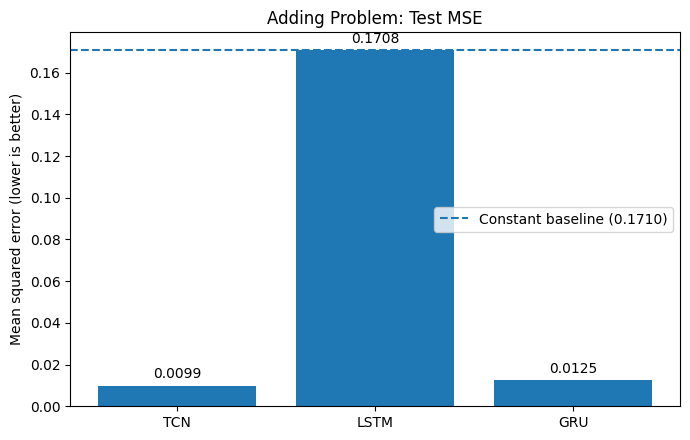

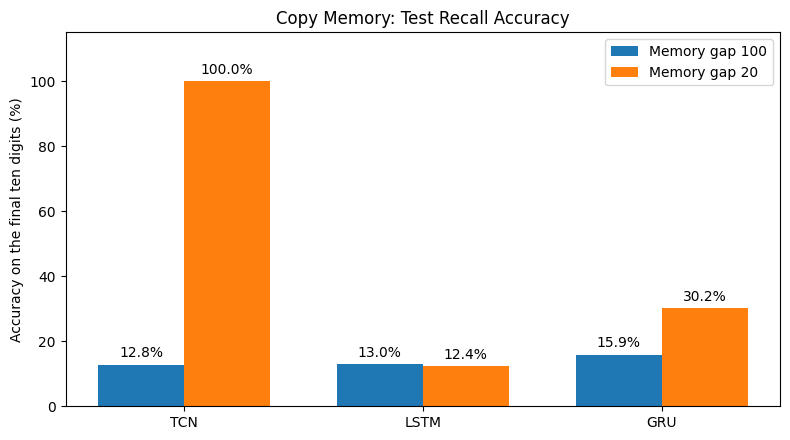

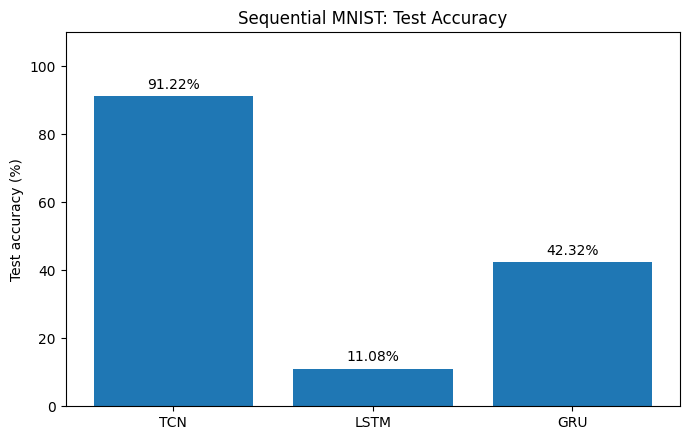

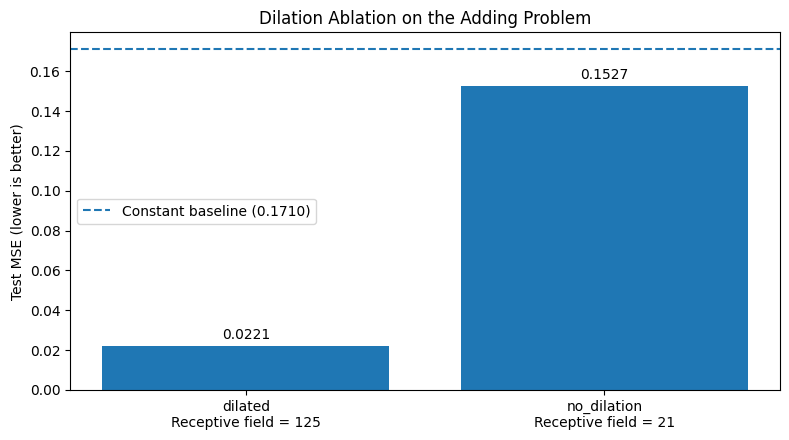


Consolidated results:


,task,configuration,model,metric,value,notes
0,Adding Problem,Sequence length 100,TCN,Test MSE,0.009946,Constant baseline MSE = 0.17104
1,Adding Problem,Sequence length 100,LSTM,Test MSE,0.170794,Constant baseline MSE = 0.17104
2,Adding Problem,Sequence length 100,GRU,Test MSE,0.012469,Constant baseline MSE = 0.17104
3,Copy Memory,Memory gap 100; total length 120,TCN,Test recall accuracy (%),12.817383,Long-gap recall experiment
4,Copy Memory,Memory gap 100; total length 120,LSTM,Test recall accuracy (%),12.998047,Long-gap recall experiment
5,Copy Memory,Memory gap 100; total length 120,GRU,Test recall accuracy (%),15.908203,Long-gap recall experiment
6,Copy Memory diagnostic,Memory gap 20; total length 40,TCN,Test digit accuracy (%),99.980469,Exact sequence accuracy = 99.80%
7,Copy Memory diagnostic,Memory gap 20; total length 40,LSTM,Test digit accuracy (%),12.421875,Exact sequence accuracy = 0.00%
8,Copy Memory diagnostic,Memory gap 20; total length 40,GRU,Test digit accuracy (%),30.214844,Exact sequence accuracy = 0.00%
9,Sequential MNIST,Train 12000; validation 2000; test 5000; 8 epochs,TCN,Test accuracy (%),91.220000,Test loss = 0.28756



Summary saved to: results/final_results_summary.csv
Plots saved to: /content/results/plots


In [14]:

# Summarize experiment results and generate plots

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = Path("results")
PLOTS_DIR = RESULTS_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

result_files = {
    "Adding Problem": "adding_comparison.csv",
    "Copy Memory — longer gap": "copy_comparison_v2.csv",
    "Copy Memory — shorter gap": "copy_comparison_v3.csv",
    "Sequential MNIST": "seq_mnist_comparison.csv",
    "Dilation ablation": "adding_dilation_ablation.csv",
}

missing = [
    filename
    for filename in result_files.values()
    if not (RESULTS_DIR / filename).exists()
]

if missing:
    raise FileNotFoundError(
        "Missing experiment results: "
        + ", ".join(missing)
        + ". Run all experiment cells before creating the plots."
    )

adding = pd.read_csv(RESULTS_DIR / result_files["Adding Problem"])
copy_long = pd.read_csv(
    RESULTS_DIR / result_files["Copy Memory — longer gap"]
)
copy_short = pd.read_csv(
    RESULTS_DIR / result_files["Copy Memory — shorter gap"]
)
mnist = pd.read_csv(
    RESULTS_DIR / result_files["Sequential MNIST"]
)
ablation = pd.read_csv(
    RESULTS_DIR / result_files["Dilation ablation"]
)

expected_models = {"TCN", "LSTM", "GRU"}

for experiment, table in [
    ("Adding Problem", adding),
    ("Copy Memory — longer gap", copy_long),
    ("Copy Memory — shorter gap", copy_short),
    ("Sequential MNIST", mnist),
]:
    if set(table["model"]) != expected_models:
        raise ValueError(
            f"Unexpected model rows in {experiment}: "
            f"{table['model'].tolist()}"
        )

print("All five experiment result files are available.")


# Adding Problem
baseline = adding["constant_baseline_test_mse"].iloc[0]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(adding["model"], adding["test_mse"])

ax.axhline(
    baseline,
    linestyle="--",
    label=f"Constant baseline ({baseline:.4f})",
)
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_title("Adding Problem: Test MSE")
ax.set_ylabel("Mean squared error (lower is better)")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "adding_problem_mse.png", dpi=200)
plt.show()
plt.close(fig)


# Copy Memory at two gap lengths
model_order = ["TCN", "LSTM", "GRU"]

long_accuracy = (
    copy_long.set_index("model")
    .reindex(model_order)["test_recall_accuracy"]
    .to_numpy() * 100
)
short_accuracy = (
    copy_short.set_index("model")
    .reindex(model_order)["test_digit_accuracy"]
    .to_numpy() * 100
)

positions = list(range(len(model_order)))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 4.5))
bars_long = ax.bar(
    [position - width / 2 for position in positions],
    long_accuracy,
    width,
    label="Memory gap 100",
)
bars_short = ax.bar(
    [position + width / 2 for position in positions],
    short_accuracy,
    width,
    label="Memory gap 20",
)

ax.bar_label(bars_long, fmt="%.1f%%", padding=3)
ax.bar_label(bars_short, fmt="%.1f%%", padding=3)
ax.set_xticks(positions, model_order)
ax.set_ylabel("Accuracy on the final ten digits (%)")
ax.set_title("Copy Memory: Test Recall Accuracy")
ax.set_ylim(0, 115)
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "copy_memory_accuracy.png", dpi=200)
plt.show()
plt.close(fig)


# Sequential MNIST
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(mnist["model"], mnist["test_accuracy"] * 100)

ax.bar_label(bars, fmt="%.2f%%", padding=3)
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Sequential MNIST: Test Accuracy")
ax.set_ylim(0, 110)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "sequential_mnist_accuracy.png", dpi=200)
plt.show()
plt.close(fig)


# Dilation ablation
labels = [
    f"{row['model'].replace('adding_ablation_', '')}\n"
    f"Receptive field = {int(row['receptive_field'])}"
    for _, row in ablation.iterrows()
]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(labels, ablation["test_mse"])

ablation_baseline = ablation["constant_baseline_test_mse"].iloc[0]
ax.axhline(
    ablation_baseline,
    linestyle="--",
    label=f"Constant baseline ({ablation_baseline:.4f})",
)
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_ylabel("Test MSE (lower is better)")
ax.set_title("Dilation Ablation on the Adding Problem")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "dilation_ablation.png", dpi=200)
plt.show()
plt.close(fig)


# Consolidate the measured results
summary_rows = []

for _, row in adding.iterrows():
    summary_rows.append({
        "task": "Adding Problem",
        "configuration": "Sequence length 100",
        "model": row["model"],
        "metric": "Test MSE",
        "value": row["test_mse"],
        "notes": f"Constant baseline MSE = {baseline:.5f}",
    })

for _, row in copy_long.iterrows():
    summary_rows.append({
        "task": "Copy Memory",
        "configuration": "Memory gap 100; total length 120",
        "model": row["model"],
        "metric": "Test recall accuracy (%)",
        "value": row["test_recall_accuracy"] * 100,
        "notes": "Long-gap recall experiment",
    })

for _, row in copy_short.iterrows():
    summary_rows.append({
        "task": "Copy Memory diagnostic",
        "configuration": "Memory gap 20; total length 40",
        "model": row["model"],
        "metric": "Test digit accuracy (%)",
        "value": row["test_digit_accuracy"] * 100,
        "notes": (
            "Exact sequence accuracy = "
            f"{row['test_exact_sequence_accuracy'] * 100:.2f}%"
        ),
    })

for _, row in mnist.iterrows():
    summary_rows.append({
        "task": "Sequential MNIST",
        "configuration": (
            f"Train {row['train_samples']}; "
            f"validation {row['validation_samples']}; "
            f"test {row['test_samples']}; "
            f"{row['epochs_completed']} epochs"
        ),
        "model": row["model"],
        "metric": "Test accuracy (%)",
        "value": row["test_accuracy"] * 100,
        "notes": f"Test loss = {row['test_loss']:.5f}",
    })

for _, row in ablation.iterrows():
    summary_rows.append({
        "task": "Adding Problem ablation",
        "configuration": (
            f"Dilation = {row['dilation']}; "
            f"receptive field = {row['receptive_field']}"
        ),
        "model": row["model"],
        "metric": "Test MSE",
        "value": row["test_mse"],
        "notes": (
            "Constant baseline MSE = "
            f"{row['constant_baseline_test_mse']:.5f}"
        ),
    })

summary = pd.DataFrame(summary_rows)
summary_path = RESULTS_DIR / "final_results_summary.csv"
summary.to_csv(summary_path, index=False)

print("\nConsolidated results:")
display(summary)

print(f"\nSummary saved to: {summary_path}")
print(f"Plots saved to: {PLOTS_DIR.resolve()}")


In [15]:

# Compare our experiments with the paper

from pathlib import Path
import pandas as pd

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

result_files = {
    "Adding Problem": "adding_comparison.csv",
    "Copy Memory": "copy_comparison_v2.csv",
    "Copy Memory diagnostic": "copy_comparison_v3.csv",
    "Sequential MNIST": "seq_mnist_comparison.csv",
    "Dilation ablation": "adding_dilation_ablation.csv",
}

missing = [
    filename
    for filename in result_files.values()
    if not (RESULTS_DIR / filename).exists()
]

if missing:
    raise FileNotFoundError(
        "Run the experiment cells first. Missing files: "
        + ", ".join(missing)
    )

adding = pd.read_csv(RESULTS_DIR / result_files["Adding Problem"])
copy_long = pd.read_csv(RESULTS_DIR / result_files["Copy Memory"])
copy_short = pd.read_csv(
    RESULTS_DIR / result_files["Copy Memory diagnostic"]
)
mnist = pd.read_csv(RESULTS_DIR / result_files["Sequential MNIST"])
ablation = pd.read_csv(RESULTS_DIR / result_files["Dilation ablation"])

# Reference values recorded from the original comparison cell.
paper_adding = {"TCN": 5.8e-5, "LSTM": 0.164, "GRU": 5.3e-5}
paper_copy = {"TCN": 3.5e-5, "LSTM": 0.0204, "GRU": 0.0197}
paper_mnist = {"TCN": 99.0, "LSTM": 87.2, "GRU": 96.2}

rows = []

for _, result in adding.iterrows():
    model = result["model"]
    rows.append({
        "task": "Adding Problem",
        "model": model,
        "paper_setting": "T = 600",
        "paper_metric": "Loss / MSE",
        "paper_value": paper_adding[model],
        "our_setting": (
            "Sequence length 100; 4096 training, 1024 validation, "
            "2048 test samples; 20 epochs"
        ),
        "our_metric": "Test MSE",
        "our_value": result["test_mse"],
        "comparison_note": (
            "Same task, but sequence length and training configuration differ."
        ),
    })

for _, result in copy_long.iterrows():
    model = result["model"]
    rows.append({
        "task": "Copy Memory",
        "model": model,
        "paper_setting": "T = 1000; total sequence length 1020",
        "paper_metric": "Loss",
        "paper_value": paper_copy[model],
        "our_setting": "Memory gap 100; total sequence length 120",
        "our_metric": "Test recall accuracy (%)",
        "our_value": 100 * result["test_recall_accuracy"],
        "comparison_note": (
            "Different sequence length and metric; numeric values "
            "are not directly comparable."
        ),
    })

for _, result in copy_short.iterrows():
    model = result["model"]
    rows.append({
        "task": "Copy Memory diagnostic",
        "model": model,
        "paper_setting": "Paper benchmark uses a longer memory gap",
        "paper_metric": "Loss",
        "paper_value": paper_copy[model],
        "our_setting": "Memory gap 20; total sequence length 40",
        "our_metric": "Test digit accuracy (%)",
        "our_value": 100 * result["test_digit_accuracy"],
        "comparison_note": (
            "Short-gap diagnostic, not a reproduction of the paper's "
            "long-memory benchmark."
        ),
    })

for _, result in mnist.iterrows():
    model = result["model"]
    rows.append({
        "task": "Sequential MNIST",
        "model": model,
        "paper_setting": "Paper benchmark; approximately 70K parameters",
        "paper_metric": "Accuracy (%)",
        "paper_value": paper_mnist[model],
        "our_setting": (
            f"{int(result['train_samples'])} training, "
            f"{int(result['validation_samples'])} validation, "
            f"{int(result['test_samples'])} test samples; "
            f"{int(result['epochs_completed'])} epochs; "
            f"{int(result['parameters']):,} parameters"
        ),
        "our_metric": "Test accuracy (%)",
        "our_value": 100 * result["test_accuracy"],
        "comparison_note": (
            "Same task and metric, but data, model size and training "
            "budget differ."
        ),
    })

for _, result in ablation.iterrows():
    rows.append({
        "task": "Adding Problem ablation",
        "model": result["model"],
        "paper_setting": "No directly corresponding result",
        "paper_metric": "N/A",
        "paper_value": None,
        "our_setting": (
            f"Dilation = {result['dilation']}; "
            f"receptive field = {int(result['receptive_field'])}"
        ),
        "our_metric": "Test MSE",
        "our_value": result["test_mse"],
        "comparison_note": (
            "Our controlled dilation experiment; not a direct paper comparison."
        ),
    })

comparison = pd.DataFrame(rows)

output_path = RESULTS_DIR / "paper_vs_our_results.csv"
comparison.to_csv(output_path, index=False)

print(f"Comparison saved to: {output_path}")
display(comparison)


Comparison saved to: results/paper_vs_our_results.csv


,task,model,paper_setting,paper_metric,paper_value,our_setting,our_metric,our_value,comparison_note
0,Adding Problem,TCN,T = 600,Loss / MSE,0.000058,"Sequence length 100; 4096 training, 1024 valid...",Test MSE,0.009946,"Same task, but sequence length and training co..."
1,Adding Problem,LSTM,T = 600,Loss / MSE,0.164000,"Sequence length 100; 4096 training, 1024 valid...",Test MSE,0.170794,"Same task, but sequence length and training co..."
2,Adding Problem,GRU,T = 600,Loss / MSE,0.000053,"Sequence length 100; 4096 training, 1024 valid...",Test MSE,0.012469,"Same task, but sequence length and training co..."
3,Copy Memory,TCN,T = 1000; total sequence length 1020,Loss,0.000035,Memory gap 100; total sequence length 120,Test recall accuracy (%),12.817383,Different sequence length and metric; numeric ...
4,Copy Memory,LSTM,T = 1000; total sequence length 1020,Loss,0.020400,Memory gap 100; total sequence length 120,Test recall accuracy (%),12.998047,Different sequence length and metric; numeric ...
5,Copy Memory,GRU,T = 1000; total sequence length 1020,Loss,0.019700,Memory gap 100; total sequence length 120,Test recall accuracy (%),15.908203,Different sequence length and metric; numeric ...
6,Copy Memory diagnostic,TCN,Paper benchmark uses a longer memory gap,Loss,0.000035,Memory gap 20; total sequence length 40,Test digit accuracy (%),99.980469,"Short-gap diagnostic, not a reproduction of th..."
7,Copy Memory diagnostic,LSTM,Paper benchmark uses a longer memory gap,Loss,0.020400,Memory gap 20; total sequence length 40,Test digit accuracy (%),12.421875,"Short-gap diagnostic, not a reproduction of th..."
8,Copy Memory diagnostic,GRU,Paper benchmark uses a longer memory gap,Loss,0.019700,Memory gap 20; total sequence length 40,Test digit accuracy (%),30.214844,"Short-gap diagnostic, not a reproduction of th..."
9,Sequential MNIST,TCN,Paper benchmark; approximately 70K parameters,Accuracy (%),99.000000,"12000 training, 2000 validation, 5000 test sam...",Test accuracy (%),91.220000,"Same task and metric, but data, model size and..."
